<a href="https://colab.research.google.com/github/yantariel/GP_ML_HW/blob/main/Seminar_2_HW_done.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнее задание к семинару 2

Задание проверяет темы семинара 2: регуляризацию, метрики классификации, деревья и ансамбли, кросс-валидацию и подбор гиперпараметров.

**Правила**
* Код пишите вместо `# <ВАШ КОД>`, переменные с `None` заполните своими значениями.
* Ячейки с пометкой `# Проверка (не изменяйте)` должны выполняться без ошибок.
* Гиперпараметры, признаки и порог подбирайте **только на обучающей выборке** (через кросс-валидацию). Тестовая выборка используется один раз, в самом конце, для итоговой оценки.
* На вопросы отвечайте текстом в ячейках «**Ответ:**», своими словами, 2–4 предложения.

**Баллы:** часть 1 — 2, часть 2 — 2.5, часть 3 — 2.5, часть 4 — 2, часть 5 — 1. Всего 10.

In [2]:
!pip install -q optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 18.2 MB/s eta 0:00:00


In [3]:
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, fetch_openml
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             precision_score, r2_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, KFold, StratifiedKFold, cross_val_predict,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Часть 1. Регуляризация (2 балла)

Датасет `diabetes` встроен в sklearn: 442 пациента, 10 признаков (возраст, пол, индекс массы тела `bmi`, давление `bp` и шесть показателей анализа крови `s1`–`s6`). Целевая переменная — количественная мера прогрессирования диабета через год после обследования.

Признаки в датасете уже отцентрированы и отнормированы.

In [4]:
X_diab, y_diab = load_diabetes(return_X_y=True, as_frame=True)
X_tr_d, X_te_d, y_tr_d, y_te_d = train_test_split(X_diab, y_diab, test_size=0.25,
                                                  random_state=RANDOM_STATE)
X_tr_d.shape, X_te_d.shape

((331, 10), (111, 10))

## 1.1 Переобучение полиномиальной модели

Постройте модель `make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), LinearRegression())`.
Посчитайте $R^2$ на обучающей и тестовой выборках.

In [5]:
poly_lr = make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), LinearRegression())

poly_lr.fit(X_tr_d, y_tr_d)  # обучение на тренировочных данных

r2_train_lr = r2_score(y_tr_d, poly_lr.predict(X_tr_d))  # считаем score на обучающей выборки  (можно еще записать как poly_lr.score(X_tr_d, y_tr_d))
r2_test_lr = r2_score(y_te_d, poly_lr.predict(X_te_d))   # считаем score на тестовой выборке
print(f"R2 train: {r2_train_lr:.3f}, R2 test: {r2_test_lr:.3f}")

R2 train: 0.910, R2 test: -55.938


In [6]:
# Проверка (не изменяйте)
assert poly_lr[0].degree == 3, "Нужна степень полинома 3"
assert r2_train_lr > 0.8 and r2_test_lr < 0, "Модель должна переобучиться: высокий R2 на train и отрицательный на test"
print("OK")

OK


## 1.2 Ridge и Lasso с подбором alpha по кросс-валидации

Замените `LinearRegression` в том же пайплайне на `Ridge`, а затем на `Lasso(max_iter=20000)`.
Для каждой модели подберите `alpha` из сетки `alphas` по среднему $R^2$ на 5-кратной кросс-валидации **на обучающей выборке**.

Используйте `cross_val_score(model, X, y, cv=cv, scoring="r2")` — функция сама делит данные на фолды, обучает модель на каждом разбиении и возвращает массив оценок.

Постройте график «среднее $R^2$ на CV в зависимости от alpha» для обеих моделей (ось X — логарифмическая).

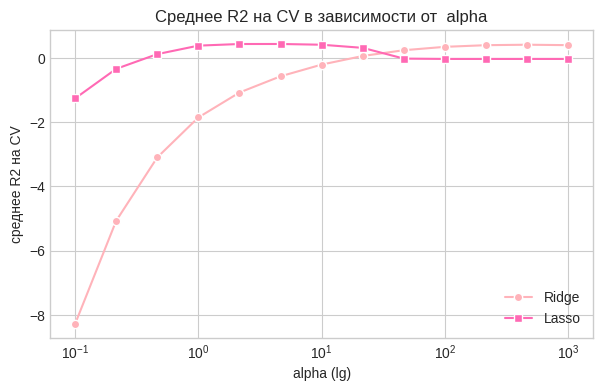

In [7]:
alphas = np.logspace(-1, 3, 13)  # 13 чисел на lg-шкале от 10^-1 до 10^3
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # делит обучающие данные на 5 частей (фолдов)

ridge_cv_scores = []  # средний R2 на CV для каждого alpha
lasso_cv_scores = []

for a in alphas:
    ridge_model = make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), Ridge(alpha=a))  # в ridge коэффициенты уменьшаются (Чем больше коэффициент  α, тем сильнее веса «прижимаются» к нулю и тем проще модель)
    lasso_model = make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), Lasso(alpha=a, max_iter=20000))  # в lasso часть коэффициентов становится 0

    ridge_cv_scores.append(cross_val_score(ridge_model, X_tr_d, y_tr_d, cv=cv_reg, scoring="r2").mean())  # берем в список среднее из 5 (на 5 фолдах) значений R2
    lasso_cv_scores.append(cross_val_score(lasso_model, X_tr_d, y_tr_d, cv=cv_reg, scoring="r2").mean())

best_alpha_ridge = alphas[int(np.argmax(ridge_cv_scores))]  # берем альфа по позиции маскимального элемента списка
best_alpha_lasso = alphas[int(np.argmax(lasso_cv_scores))]

# график
plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(7, 4))
plt.semilogx(alphas, ridge_cv_scores, "o-", color='#FFB3BA', markeredgecolor='white', label="Ridge")    # логарифмическая шкала только по x
plt.semilogx(alphas, lasso_cv_scores, "s-", color='#FF69B4', markeredgecolor='white', label="Lasso")
plt.xlabel("alpha (lg)")
plt.ylabel("среднее R2 на CV")
plt.title("Среднее R2 на CV в зависимости от  alpha")
plt.legend()
plt.show()

Обучите Ridge и Lasso с лучшими `alpha` на всей обучающей выборке и посчитайте $R^2$ на тесте.
Для Lasso посчитайте, сколько коэффициентов из 285 осталось ненулевыми.

In [8]:
ridge_best = make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), Ridge(alpha=best_alpha_ridge)).fit(X_tr_d, y_tr_d)
lasso_best = make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), Lasso(alpha=best_alpha_lasso, max_iter=20000)).fit(X_tr_d, y_tr_d)

r2_test_ridge = r2_score(y_te_d, ridge_best.predict(X_te_d))
r2_test_lasso = r2_score(y_te_d, lasso_best.predict(X_te_d))

lasso_coefs = lasso_best[-1].coef_  # lasso_best[-1].coef_ - массив обученных коэффициентов lasso
n_nonzero_lasso = (lasso_coefs != 0).sum()  # число ненулевых коэффициентов lasso, # в lasso-регрессии штрафуется сумма модулей весов, штраф обращает часть весов в точный ноль — модель сама отбирает признаки

print(f"Ridge (alpha={best_alpha_ridge:.2f}): R2 test = {r2_test_ridge:.3f}")
print(f"Lasso (alpha={best_alpha_lasso:.2f}): R2 test = {r2_test_lasso:.3f}, ненулевых коэффициентов: {n_nonzero_lasso}")

Ridge (alpha=464.16): R2 test = 0.436
Lasso (alpha=4.64): R2 test = 0.511, ненулевых коэффициентов: 21


In [9]:
# Проверка (не изменяйте)
assert len(ridge_cv_scores) == len(alphas) and len(lasso_cv_scores) == len(alphas)
assert r2_test_ridge > 0.35, "Ridge с подобранным alpha должен заметно превзойти LinearRegression"
assert r2_test_lasso > 0.45, "Lasso с подобранным alpha должен давать R2 > 0.45"
assert 0 < n_nonzero_lasso < 285
print("OK")

OK


## 1.3 Путь регуляризации Lasso

На **исходных 10 признаках** (без полиномов) обучите `Lasso` для каждого `alpha` из `path_alphas` и сохраните коэффициенты в массив `coefs` размера `(40, 10)`.
Постройте график: по оси X — alpha (логарифмическая шкала), по оси Y — коэффициенты, по одной линии на признак, с легендой.

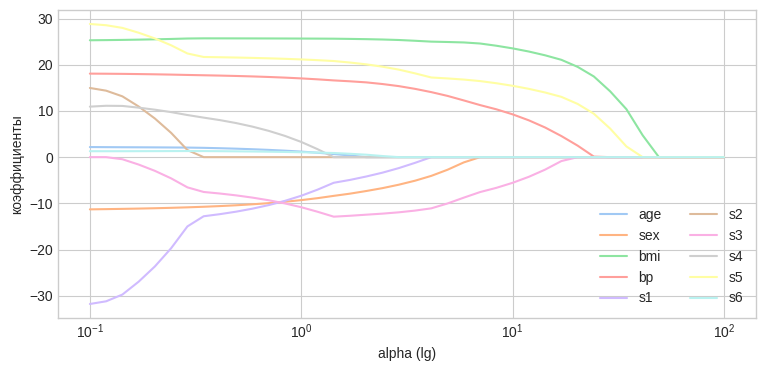

In [10]:
import seaborn as sns

path_alphas = np.logspace(-1, 2, 40)
scaler_d = StandardScaler().fit(X_tr_d)  # стандартизируем признаки, потому что lasso чувствителен к масштабу
X_tr_d_scaled = scaler_d.transform(X_tr_d)

coefs = np.array([Lasso(alpha=a, max_iter=20000).fit(X_tr_d_scaled, y_tr_d).coef_ for a in path_alphas])  # для каждого alpha обучаем lasso и берем его коэффициенты .coef_, np.array делает табличку (40 альфа, 10 коэффициентов lasso)

# график
palette = sns.color_palette("pastel", n_colors=len(X_tr_d.columns))  # пастельные цвета для графика
plt.figure(figsize=(9, 4))
# enumerate даёт пары (номер, имя) для каждого столбца; coefs[:, j] - весь столбец j (коэффициент признака j при всех alpha)
for j, name in enumerate(X_tr_d.columns):
    plt.semilogx(path_alphas, coefs[:, j], color=palette[j], label=name)
plt.xlabel("alpha (lg)")
plt.ylabel("коэффициенты")
plt.legend(ncol=2)                      # легенда в две колонки
plt.show()

Какие **два** признака Lasso обнуляет последними? Запишите их названия в `last_two` (порядок не важен).

In [11]:
last_two = ["s5", "bmi"]  # самые поздно входящие в 0 линии

In [12]:
# Проверка (не изменяйте)
assert coefs.shape == (40, 10)
assert hashlib.md5(",".join(sorted(last_two)).encode()).hexdigest() == "13f104a52a26582f52733f857055217f", "Посмотрите на график ещё раз"
print("OK")

OK


**Вопрос 1.** Почему LinearRegression на полиномах 3-й степени дала отрицательный $R^2$ на тесте, а Ridge и Lasso — нет? Чем отличается то, как Ridge и Lasso «борются» с лишними признаками?

**Ответ:** LinearRegression дала отрицательный R2 из-за переобучения. Отрицательный R2 на тесте означает, что модель ошибается сильнее, чем просто предсказание по среднему значениям целевой переменной. Полином 3й степени порождает много производных признаков и число параметров может стать сопоставимым или даже больше, чем число наблюдений (что у нас и происходит), модель начинает подгоняться под шумы. LinearRegression подбирает огромные по модулю коэффициенты, чтобы максимально точно описать обучающую выборку (пройти через train), а на новых (тестовых) данных такие большие коэффициенты дают резкие выбросы ошибок, из-за чего R2 становится отрицательным.
Ridge и Lasso борются с переобучением, штрафуя модель за слишком большие веса. Их отличие заключается в типе регуляризации. (сила регуляризации задается параметром alpha, его нужно подбирать, мы в работе делали это через кросс‑валидацию (CV))
Ridge-регрессия (использует L2-регуляризацию) уменьшает коэффициенты, "прижимает" их к нулю, но не обращает в ноль (так как штрафуется сумма квадратов коэффициентов), то есть не дает сильно коррелированным признакам "раздуться" до огромных значений.
Lasso-регрессия (использует L1-регуляризацию) обращает часть весов в ноль (штрафуется сумма модулей), сама отбирает признаки (в случае полиномиальных моделей убирает наименее значимые полиномиальные члены), фактически удаляя их из модели.


# Часть 2. Предсказание отказов оборудования (2.5 балла)

Датасет [AI4I 2020 Predictive Maintenance](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset) — синтетические, но реалистичные данные о работе фрезерного станка: 10 000 записей.

| Столбец | Описание |
|---|---|
| `type` | качество изделия: L (низкое), M (среднее), H (высокое) |
| `air_temp`, `process_temp` | температура воздуха и процесса, К |
| `rpm` | скорость вращения шпинделя, об/мин |
| `torque` | крутящий момент, Н·м |
| `tool_wear` | износ инструмента, мин |
| **`failure`** | **целевая переменная: 1 — произошёл отказ** |
| `TWF`, `HDF`, `PWF`, `OSF`, `RNF` | тип отказа: износ инструмента, перегрев, мощность, перегрузка, случайный |
| `UDI`, `Product ID` | идентификаторы |

Задача: по показаниям датчиков предсказать отказ.

In [13]:
df = fetch_openml(data_id=42890, as_frame=True, parser="auto").frame
df = df.rename(columns={
    "Type": "type",
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rpm",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Machine failure": "failure",
})
df.head()

,UDI,Product ID,type,air_temp,process_temp,rpm,torque,tool_wear,failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2.1 Подготовка признаков

Соберите матрицу признаков `X` и целевую переменную `y`:
* удалите идентификаторы `UDI` и `Product ID`;
* удалите целевую переменную и **столбцы с типами отказов** — они известны только после того, как отказ случился, и в момент прогноза их нет;
* закодируйте `type` через one-hot (`pd.get_dummies(..., columns=["type"], dtype=float)`).

Посчитайте долю отказов в данных.

In [14]:
FAILURE_TYPES = ["TWF", "HDF", "PWF", "OSF", "RNF"]

X = df.drop(columns=["UDI", "Product ID", "failure"] + FAILURE_TYPES)  # возвращаем таблицу без столбцов идентификаторов (потому что это просто номера, там не может быть закономерностей), целевой переменной failure и типов отказов
X = pd.get_dummies(X, columns=["type"], dtype=float)  # кодируем признак type (он текстовый, мы заменяем его на столбцы type_H, type_L, type_M со значениями 1 или 0 (bool (True/False))
y = df["failure"].astype(int)  # целевая переменная

failure_rate = y.mean()
print(f"Доля отказов: {failure_rate:.2%}")
X.head()

Доля отказов: 3.39%


,air_temp,process_temp,rpm,torque,tool_wear,type_H,type_L,type_M
0,298.1,308.6,1551,42.8,0,0.0,0.0,1.0
1,298.2,308.7,1408,46.3,3,0.0,1.0,0.0
2,298.1,308.5,1498,49.4,5,0.0,1.0,0.0
3,298.2,308.6,1433,39.5,7,0.0,1.0,0.0
4,298.2,308.7,1408,40.0,9,0.0,1.0,0.0


In [15]:
# Проверка (не изменяйте)
assert X.shape == (10000, 8), f"Ожидалось 8 признаков, получилось {X.shape[1]}"
assert not set(FAILURE_TYPES + ["failure", "UDI", "Product ID"]) & set(X.columns), "В признаках остались лишние столбцы"
assert abs(failure_rate - 0.0339) < 1e-4
print("OK")

OK


Разбиение на обучающую и тестовую выборки (не изменяйте). Параметр `stratify=y` сохраняет долю отказов одинаковой в обеих частях — при редком классе это важно.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y,
                                                    random_state=RANDOM_STATE)
y_train.mean(), y_test.mean()

(np.float64(0.03386666666666667), np.float64(0.034))

## 2.2 Базовые модели и метрики

Обучите на `X_train`:
* `DummyClassifier()` — всегда предсказывает самый частый класс;
* `make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))`.

Для каждой модели посчитайте на `X_test` accuracy, precision, recall, ROC-AUC и PR-AUC (`average_precision_score`; для ROC-AUC и PR-AUC нужны вероятности из `predict_proba`, а не метки классов).
Сложите результаты в таблицу `metrics` (строки — модели `"dummy"` и `"logreg"`, столбцы — `"accuracy"`, `"precision"`, `"recall"`, `"roc_auc"`, `"pr_auc"`). Выведите матрицу ошибок логистической регрессии.

In [17]:
dummy = DummyClassifier().fit(X_train, y_train)  # любая разумная модель должна быть лучше DummyClassifier
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)  # обучаемая модель

dummy_pred = dummy.predict(X_test)  # всегда предсказывает самый частый класс
logreg_pred = logreg.predict(X_test)  # модель считает вероятность и сравнивает ее с порогом 0.5 (по умолчанию в методе predict), больше порога: ответ отказ (метка 1), меньше - нет отказа (метка 0)

dummy_proba = dummy.predict_proba(X_test)[:, 1]  # predict_proba возвращает таблицу из двух столбцов: [P(класс 0), P(класс 1)] (то есть вероятности отсутствия отказа/отказа)
logreg_proba = logreg.predict_proba(X_test)[:, 1]

# таблица метрик: строки — модели, столбцы — метрики
metrics = pd.DataFrame({
    "accuracy":  [accuracy_score(y_test, dummy_pred), accuracy_score(y_test, logreg_pred)],
    "precision": [precision_score(y_test, dummy_pred, zero_division=0), precision_score(y_test, logreg_pred, zero_division=0)], # zero_division=0: если модель ни разу не предсказала "отказ", precision = 0/0 - в этом случае считаем 0, без предупреждения
    "recall":    [recall_score(y_test, dummy_pred), recall_score(y_test, logreg_pred)],
    "roc_auc":   [roc_auc_score(y_test, dummy_proba), roc_auc_score(y_test, logreg_proba)], # ROC-AUC и PR-AUC считаются по вероятностям, а не по меткам
    "pr_auc":    [average_precision_score(y_test, dummy_proba), average_precision_score(y_test, logreg_proba)],
}, index=["dummy", "logreg"])

print("Матрица ошибок logreg (строки — истина, столбцы — прогноз):")
print(confusion_matrix(y_test, logreg_pred))
metrics

Матрица ошибок logreg (строки — истина, столбцы — прогноз):
[[2407    8]
 [  73   12]]


,accuracy,precision,recall,roc_auc,pr_auc
dummy,0.9660,0.0,0.000000,0.500000,0.034000
logreg,0.9676,0.6,0.141176,0.876751,0.405501


In [18]:
# Проверка (не изменяйте)
assert set(metrics.index) == {"dummy", "logreg"}
assert set(metrics.columns) >= {"accuracy", "precision", "recall", "roc_auc", "pr_auc"}
assert metrics.loc["dummy", "accuracy"] > 0.96 and metrics.loc["dummy", "recall"] == 0
assert metrics.loc["logreg", "roc_auc"] > 0.85
assert metrics.loc["logreg", "pr_auc"] < metrics.loc["logreg", "roc_auc"]
print("OK")

OK


**Вопрос 2.** У DummyClassifier accuracy около 0.97. Почему эта модель бесполезна для задачи, и почему PR-AUC здесь информативнее, чем accuracy и ROC-AUC?

**Ответ:** Accuracy DummyClassifier равна доле самого частого класса (0 - отказа нет), это ничего не говорит о качестве модели - ее способности выявлять отказы. Recall DummyClassifier равен 0 (из таблицы metrics), то есть ни одного реального отказа он не поймает, хотя именно это обнаружение редких отказов и является целью задачи.
Accuracy плохо работает при дисбалансе классов и бесполезна для задачи, где нужно находить редкие случаи. Ее формула: accuracy = (TP + TN) / (TP + TN + FP + FN), где TP = True Positive, TN = True Negative, FP = False Positive, FN = False Negative. При сильном дисбалансе значение accuracy фактически определяется долей TN, которых у нас в выборке большинство, это маскирует неспособность модели находить редкие положительные случаи (отказы оборудования).
ROC-AUC оценивает вероятность того, что модель присвоит более высокую оценку объекту положительного класса, чем отрицательного. Он считает долю ложных срабатываний (FPR (False Positive Rate) = FP / (FP + TN)), а при большом числе TN даже при большом числе FP знаменатель огромный, и FPR получается маленьким, метрика кажется завышенной. Поэтому высокий ROC‑AUC не гарантирует, что модель полезна для практики. (у нас из таблицы metrics ROC-AUC логрегрессии ≈ 0.88, хотя recall ≈ всего 0.14).
PR-AUC не зависит от TN, а считается только по положительному классу — через precision и recall. Precision = TP / (TP + FP) — показывает, из всех объектов, которые модель назвала отказом, сколько действительно были отказами; recall = TP / (TP + FN) — сколько реальных отказов модель вообще смогла найти. Поэтому при поиске редких событий PR-AUC — самая информативная метрика: она показывает именно то, что нас интересует, — способность модели находить редкий (положительный) класс и балансировать между полнотой обнаружения и числом ложных срабатываний (в DummyClassifier PR-AUC = 0.034, а в logreg уже 0.41).


## 2.3 Утечка данных

Проведите эксперимент: обучите ту же логистическую регрессию, добавив к признакам столбцы с типами отказов `FAILURE_TYPES` (используйте те же индексы train/test). Посчитайте ROC-AUC на тесте.

In [19]:
X_train_leak = pd.concat([X_train, df.loc[X_train.index, FAILURE_TYPES]], axis=1)  # добавляем стобцы с типами отказов к признакам (df.loc - берем из df те же строки, что в train/test, и столбцы с типами отказов,
X_test_leak = pd.concat([X_test, df.loc[X_test.index, FAILURE_TYPES]], axis=1)     # с помощью pd.concat([..., ...], axis=1) приклеиваем таблицы друг к другу по столбцам (axis=1), строки сопоставляются по индексу)

logreg_leak = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train_leak, y_train)
roc_auc_leak = roc_auc_score(y_test, logreg_leak.predict_proba(X_test_leak)[:, 1])
print(f"ROC-AUC с типами отказов: {roc_auc_leak:.3f}")

ROC-AUC с типами отказов: 0.978


In [20]:
# Проверка (не изменяйте)
assert roc_auc_leak > 0.95
print("OK")

OK


**Вопрос 3.** Почему качество так выросло? Можно ли использовать такую модель на реальном станке? Приведите пример похожей утечки из вашей предметной области.

**Ответ:** Качество выросло, потому что мы добавили столбцы с причинами отказа - по сути ответы (это прямая информация о целевом событии). На реальном станке такую модель нельзя использовать, так как причины отказа станут известны лишь после того, как этот отказ произошел, а наша модель должна его предсказать заранее. Модель, обученная с такой утечкой, в реальных условиях покажет случайное угадывание.
По результатам обучения "Зайти в АйТи" мне нужно обучить модель для предсказания отказа опорного подшипника ГТД. У меня нет готовой разметки отказов, и я должна сама найти моменты ухода двигателя в аварию, например по аномальному росту вибрации. Если я размечу эти моменты как "отказ" по признаку V1 (вибрация промежуточного корпуса газогенератора) и оставлю V1 в признаках модели, то модель выучит мое же правило разметки: V1 превысил порог - значит отказ. Это будет не предсказанием, а воспроизведением моей ручной разметки. При этом сам отказ подшипника может развиваться постепенно, и за 30 минут до аварии V1 может быть ещё в пределах нормы — тогда модель не сработает.

# Часть 3. Деревья, ансамбли и кросс-валидация (2.5 балла)

## 3.1 Сравнение моделей

Сравните четыре модели по PR-AUC на 5-кратной **стратифицированной** кросс-валидации на обучающей выборке (`scoring="average_precision"`):
* логистическая регрессия (как в 2.2);
* `DecisionTreeClassifier(random_state=RANDOM_STATE)`;
* `RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)`;
* `XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1)`.

Сохраните результаты в таблицу `cv_results`: строки — `"logreg"`, `"tree"`, `"forest"`, `"xgb"`, столбцы — `"mean"` и `"std"`.

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "tree": DecisionTreeClassifier(random_state=RANDOM_STATE),   # модель, которая строит дерево решений — последовательность вопросов «да/нет», которые ведут к ответу (дерево рекурсивно выбирает лучший признак и порог, чтобы разделить данные на две группы так, чтобы они стали как можно чище)
    "forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),   # параллельно строится много деревьев (.n_estimators=300 число деревьев), их ответы усредняются. Каждое дерево обучается на случайной бутстрэп-подвыборке объектов, а при каждом разбиении рассматривается случайное подмножество признаков
    "xgb": XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1),  # градиентный бустинг, вычислив градиент этой функции по предсказаниям ансамбля из N деревьев, можно обучить (N+1)-е дерево так, чтобы оно как можно сильнее уменьшило функцию потерь (деревья строятся последовательно друг за другом, каждое исправляет ошибки предыдущих)
}

rows = {}

for name, model in models.items():  # .items() дает пары словаря (ключ, значение)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="average_precision")
    rows[name] = {"mean": scores.mean(), "std": scores.std()}   # std - разброс, чем меньше, тем стабильнее модель

cv_results = pd.DataFrame(rows).T  # .T транспонирует (чтобы модели были строками, а mean/std столбцами)
cv_results

,mean,std
logreg,0.477186,0.042771
tree,0.470946,0.049100
forest,0.772921,0.024853
xgb,0.779277,0.039048


In [22]:
# Проверка (не изменяйте)
assert set(cv_results.index) == {"logreg", "tree", "forest", "xgb"}
assert cv_results.loc[["forest", "xgb"], "mean"].min() > cv_results.loc[["logreg", "tree"], "mean"].max() + 0.1, \
    "Ансамбли должны заметно обгонять одиночное дерево и логистическую регрессию"
print("OK")

OK


## 3.2 Важность признаков

Обучите случайный лес на всей обучающей выборке и постройте столбчатую диаграмму `feature_importances_`, отсортированную по убыванию.

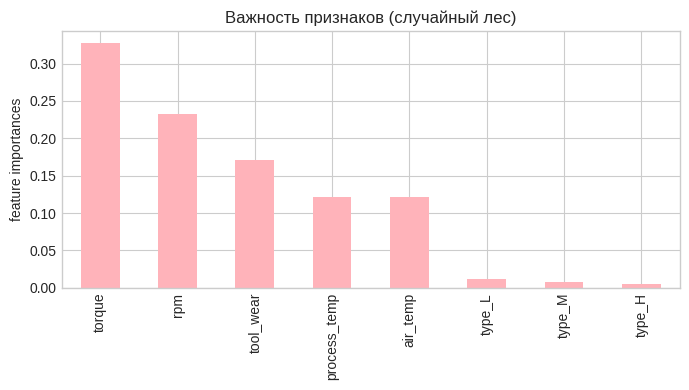

In [35]:
model = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)   # создаем и обучаем модель
# rf.feature_importances_ - массив важностей (по одной на признак).
importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)  # создаем массив чисел, показывающих важность соответствующего признака, pd.Series сопоставляет его с названиями признаков, sort_values(ascending=False) сортирует по убыванию

plt.figure(figsize=(7, 4))
importances.plot.bar(color='#FFB3BA')          # столбчатая диаграмма важности признаков
plt.ylabel("feature importances")
plt.title("Важность признаков (случайный лес)")
plt.tight_layout()              # чтобы подписи не обрезались
plt.show()

#importances

## 3.3 Признаки из физики процесса

Отказы в этом датасете вызваны физическими причинами: перегрев (мала разница температур при низкой скорости), отказ по мощности (мощность вне допустимого диапазона), перегрузка (износ × момент слишком велик).
Напишите функцию `add_physics_features`, которая добавляет к таблице три признака:
* `power` — механическая мощность, Вт: $P = M \cdot \omega$, где $\omega = 2\pi \cdot \text{rpm} / 60$;
* `temp_diff` — разность `process_temp - air_temp`;
* `strain` — произведение `tool_wear * torque`.

Сравните PR-AUC на CV для логистической регрессии и XGBoost без новых признаков и с ними.

In [37]:
def add_physics_features(data):
    data = data.copy()
    omega = 2 * np.pi * data["rpm"] / 60  # угловая скорость w
    data["power"] = data["torque"] * omega                          # механическая мощность, torque - крутящий момент
    data["temp_diff"] = data["process_temp"] - data["air_temp"]     # разность температур
    data["strain"] = data["tool_wear"] * data["torque"]             # напряжение (износ * момент)
    return data

X_train_fe = add_physics_features(X_train)  # применяем функцию к train и test
X_test_fe = add_physics_features(X_test)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "xgb": XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1),
}

scores_logreg_base = cross_val_score(models["logreg"], X_train, y_train,cv=cv, scoring="average_precision", n_jobs=-1).mean()
scores_logreg_fe = cross_val_score(models["logreg"], X_train_fe, y_train,cv=cv, scoring="average_precision", n_jobs=-1).mean()

scores_xgb_base = cross_val_score(models["xgb"], X_train, y_train,cv=cv, scoring="average_precision", n_jobs=-1).mean()
scores_xgb_fe = cross_val_score(models["xgb"], X_train_fe, y_train,cv=cv, scoring="average_precision", n_jobs=-1).mean()

fe_results = pd.DataFrame({   # словарь словарей: внешние ключи ("base", "physics") станут столбцами, а внутренние ("logreg", "xgb") строками
    "base": {
        "logreg": scores_logreg_base,
        "xgb":    scores_xgb_base,
    },
    "physics": {                     # с новыми признаками
        "logreg": scores_logreg_fe,
        "xgb":    scores_xgb_fe,
    },
})
fe_results

,base,physics
logreg,0.477186,0.508758
xgb,0.779277,0.861129


In [38]:
# Проверка (не изменяйте)
assert {"power", "temp_diff", "strain"} <= set(X_train_fe.columns)
assert abs(X_train_fe["power"].median() - 6100) < 300, "Проверьте формулу мощности"
assert fe_results.loc["xgb", "physics"] > fe_results.loc["xgb", "base"] + 0.03
print("OK")

OK


**Вопрос 4.** XGBoost заметно выиграл от новых признаков, а логистическая регрессия — почти нет. Почему? Подсказка: отказ по мощности случается, когда мощность **либо слишком мала, либо слишком велика**.

**Ответ:** Логистическая регрессия — линейная модель, поэтому зависимость между признаком и вероятностью отказа у нее прямая: с ростом мощности вероятность отказа либо монотонно растет, либо монотонно падает. Однако отказ по мощности возникает и при слишком малой, и при слишком большой мощности — то есть зависимость имеет U-образную форму (из описания датасета: "power failure (PWF): the product of torque and rotational speed (in rad/s) equals the power required for the process. If this power is below 3500 W or above 9000 W, the process fails"). Такая зависимость нелинейна, и линейная модель не способна ее описать — отсюда слабый прирост от нового признака (из таблицы fe_results рост от 0.48 до 0.51). Для логистической регрессии произведение признаков — это просто еще один линейный член: если зависимость от этого произведения немонотонна, модель снова не сможет её корректно отразить. Линейная модель вынуждена выбирать «среднее направление» и в итоге плохо предсказывает оба «хвоста» распределения. Поэтому даже добавление признака power не спасает ситуацию — сама структура модели не позволяет ей закодировать условие «мало или много».
XGBoost состоит из деревьев решений, которые разбивают значения признака на интервалы. Получив готовый признак power, XGBoost описывает U-образную зависимость буквально двумя разбиениями (power < 3500 и power > 9000), не тратя ресурс на восстановление формулы power = torque · ω. То же самое со strain = tool_wear · torque: это произведение исходных признаков, которое дереву без готового признака пришлось бы приближать множеством разрезов. Такой признак заранее «упаковывает» взаимодействие двух переменных — дереву проще сделать одно разбиение по готовому признаку, чем самостоятельно восстанавливать нелинейное взаимодействие через комбинации разбиений по отдельным признакам. Поэтому XGBoost выигрывает от feature engineering значительно сильнее, чем линейная модель (из таблицы fe_results рост с 0.78 до 0.86).

# Часть 4. Подбор гиперпараметров и выбор порога (2 балла)

Дальше работаем с XGBoost на признаках `X_train_fe`.

## 4.1 Optuna

Напишите функцию `objective(trial)`, которая предлагает гиперпараметры XGBoost и возвращает средний PR-AUC на кросс-валидации `cv` по `X_train_fe`. Подбирайте как минимум `n_estimators` (100–600), `max_depth` (2–8), `learning_rate` (0.01–0.3, логарифмическая шкала), `subsample` (0.6–1.0), `min_child_weight` (1–10).
Запустите 30 испытаний.

In [43]:
import time  # модуль для замера времени работы
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)  # устанавливаем уровень логирования WARNING — будут показаны только ошибки


def objective(trial):   # каждый trial.suggest_* просит у Optuna очередное значение из заданного диапазона
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 600),                    # число деревьев, чем больше деревьев, тем точнее модель, но дольше обучение
        "max_depth": trial.suggest_int("max_depth", 2, 8),                              # макс. глубина одного дерева, слишком маленькая глубина → недообучение, слишком большая → переобучение
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),     # learning_rate — скорость обучения, лог шкала
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),                        # доля объектов, на которой обучается каждое дерево, меньше 1.0 = регуляризация (каждое дерево видит свою часть данных), это помогает бороться с переобучением
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),               # минимальный суммарный вес объектов в листе, защита от переобучения
    }
    model = XGBClassifier(**params, random_state=RANDOM_STATE, n_jobs=-1)  # **params распаковывает словарь в именованные аргументы: XGBClassifier(n_estimators=..., max_depth=..., и тд)
    return cross_val_score(model, X_train_fe, y_train, cv=cv, scoring="average_precision").mean()   # возвращаем средний PR-AUC на CV


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
t0 = time.perf_counter()  # засекаем время до запуска
study.optimize(objective, n_trials=30, show_progress_bar=True)  # запускаем оптимизацию, n_trials=30 - 30 испытаний (30 разных комбинаций гиперпараметров)
time_optuna = time.perf_counter() - t0  # прошедшее время = текущее - начальное
print("Лучший PR-AUC на CV:", study.best_value)
print("Лучшие параметры:", study.best_params)

  0%|          | 0/30 [00:00<?, ?it/s]

Лучший PR-AUC на CV: 0.8838056287739336
Лучшие параметры: {'n_estimators': 275, 'max_depth': 5, 'learning_rate': 0.013884929367199216, 'subsample': 0.6654060090277754, 'min_child_weight': 1}


In [44]:
# Проверка (не изменяйте)
assert len(study.trials) >= 30
assert study.best_value > 0.85
print("OK")

OK


## 4.2 Сравнение с GridSearchCV

Подберите те же гиперпараметры через `GridSearchCV` с сопоставимым бюджетом — **не больше 30 комбинаций** в сетке. Сравните лучший результат на CV и время работы с Optuna.

In [45]:
param_grid = {  # должно быть не более 30 комбинаций, тут 24
    "n_estimators": [200, 500],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.03, 0.1],
    "subsample": [0.8, 1.0],
}

grid = GridSearchCV(XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1), param_grid, scoring="average_precision", cv=cv, n_jobs=1)
t0 = time.perf_counter()  # засекаем время до запуска
grid.fit(X_train_fe, y_train)            # перебирает все комбинации и обучается заново на лучшей
time_grid = time.perf_counter() - t0     # прошедшее время = текущее - начальное

print("Комбинаций в сетке:", len(grid.cv_results_["params"]))
print("Лучший PR-AUC на CV:", grid.best_score_)
print("Лучшие параметры:", grid.best_params_)
print(f"Время GridSearchCV: {time_grid:.0f} с (Optuna: {time_optuna:.0f} с)")

Комбинаций в сетке: 24
Лучший PR-AUC на CV: 0.8875559329787943
Лучшие параметры: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200, 'subsample': 1.0}
Время GridSearchCV: 76 с (Optuna: 63 с)


In [46]:
# Проверка (не изменяйте)
assert len(grid.cv_results_["params"]) <= 30
assert grid.scoring == "average_precision"
print("OK")

OK


## 4.3 Выбор порога по стоимости ошибок

Модель выдаёт вероятность отказа, а решение «останавливать станок на обслуживание или нет» принимается по порогу. Пусть **пропущенный отказ стоит 20 условных единиц, а ложная тревога — 1**.

1. Возьмите XGBoost с лучшими параметрами Optuna и получите **out-of-fold** вероятности на обучающей выборке: `cross_val_predict(model, X_train_fe, y_train, cv=cv, method="predict_proba")`. Каждая вероятность в них предсказана моделью, которая этот объект не видела.
2. Подберите по ним порог из `thresholds`, минимизирующий суммарную стоимость ошибок.
3. Обучите модель на всей обучающей выборке и **один раз** оцените её на тесте: PR-AUC и стоимость ошибок при подобранном пороге и при пороге 0.5.

In [47]:
COST_FN, COST_FP = 20, 1  # стоимость пропущенного отказа (станок сломался, большой ущерб) и стоимость ложной тревоги (лишний осмотр, маленький ущерб)
thresholds = np.linspace(0.005, 0.995, 199)  # массив кандидатов в пороги от 0.005 до 0.995


def total_cost(y_true, proba, threshold):  # считает суммарную стоимость ошибок при заданном пороге, y_true - истинные метки (0/1), proba - предсказанные вероятности отказа, threshold - порог, выше которого предсказываем отказ
    y_pred = (proba > threshold).astype(int)
    fp = ((y_true == 0) & (y_pred == 1)).sum()  # fp — false positive, ложная тревога, (y_true == 0) & (y_pred == 1) → True там, где FP
    fn = ((y_true == 1) & (y_pred == 0)).sum()  # fn — false negative, пропущенный отказ
    return COST_FN * fn + COST_FP * fp

best_model = XGBClassifier(**study.best_params, random_state=RANDOM_STATE, n_jobs=-1)  # модель XGBoost с лучшими параметрами из Optuna (** - распаковка словаря параметров)
oof_proba = cross_val_predict(best_model, X_train_fe, y_train, cv=cv, method="predict_proba")[:, 1]  # oof = out-of-fold вероятности на train: каждая предсказана моделью, не видевшей этот объект
                                                                                                     # method="predict_proba" - возвращать вероятности; [:, 1] - берем вероятности класса отказ
oof_costs = np.array([total_cost(y_train, oof_proba, t) for t in thresholds])  # для каждого кандидата в порог считаем стоимость

best_threshold = thresholds[int(np.argmin(oof_costs))]  # argmin - позиция минимальной стоимости, по ней берем соответствующий порог

final_model = XGBClassifier(**study.best_params, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_fe, y_train)  # финальная модель: обучаем на всей обучающей выборке и впервые смотрим тест
test_proba = final_model.predict_proba(X_test_fe)[:, 1]   # вероятности отказа на тесте

test_pr_auc = average_precision_score(y_test, test_proba)
cost_best = total_cost(y_test, test_proba, best_threshold)  # стоимость при подобранном пороге
cost_05 = total_cost(y_test, test_proba, 0.5)               # при стандартном пороге 0.5
cost_never = total_cost(y_test, test_proba, 1.01)  # никогда не останавливать станок

print(f"PR-AUC на тесте: {test_pr_auc:.3f}")
print(f"Порог {best_threshold:.3f}: стоимость {cost_best}")
print(f"Порог 0.5: стоимость {cost_05}")
print(f"Без модели: стоимость {cost_never}")

PR-AUC на тесте: 0.877
Порог 0.035: стоимость 219
Порог 0.5: стоимость 348
Без модели: стоимость 1700


In [48]:
# Проверка (не изменяйте)
assert total_cost(np.array([1, 0, 1, 0]), np.array([0.9, 0.9, 0.1, 0.1]), 0.5) == COST_FN + COST_FP
assert cost_never == COST_FN * y_test.sum()
assert best_threshold < 0.5, "При дорогих пропусках порог должен быть ниже 0.5"
assert cost_best < cost_05
assert test_pr_auc > 0.8
print("OK")

OK


# Часть 5. Выводы (1 балл)

**Вопрос 5.** Представьте, что модель внедряют для мониторинга реальных станков. Ответьте на вопросы:
* Какую модель и какой порог вы бы выбрали и почему?
* Почему порог подбирался по out-of-fold предсказаниям на train, а не по тесту?
* Что изменится, если пропуск отказа будет стоить не 20, а 200? Что ещё, кроме стоимости ошибок, нужно учесть перед внедрением?

**Ответ:**
1) Для мониторинга станков я бы выбрала XGBoost на физических признаках (power, temp_diff, strain) с гиперпараметрами из Optuna. Это классификационная модель, которая предсказывает состояние станка по данным с датчиков. По результатам кросс-валидации XGBoost с новыми признаками показал PR-AUC ≈ 0.88, и на тесте оценка подтвердилась на том же уровне — это заметно выше логистической регрессии, которая не способна уловить нелинейную зависимость вероятности отказа от мощности. Порог — около 0.035, подобранный по out-of-fold вероятностям: при цене пропуска 20 и ложной тревоги 1 выгодно останавливать станок уже при вероятности отказа в несколько процентов (теоретический порог для откалиброванных вероятностей 1/(1+20) ≈ 0.05). Порог 0.5 здесь неоптимален, потому что он предполагает равную цену ошибок, а у нас пропуск в 20 раз дороже тревоги. На тесте подобранный порог даёт стоимость 219 против 348 при пороге 0.5 и 1700 без модели — то есть почти в 8 раз меньше, чем если вообще не использовать модель.

2) Порог подбирался по out-of-fold предсказаниям на train, потому что тест должен быть использован один раз — для итоговой честной оценки. Если подбирать порог по тесту, оценка стоимости окажется завышенной: порог будет подогнан под те же данные, и на новых реальных станках модель отработает хуже, чем показала. Предсказания на самом train тоже не годятся: модель уже видела эти объекты, её вероятности завышены (для отказов ближе к 1, для норм ближе к 0), и порог по ним будет смещён. Out-of-fold вероятности лишены этого недостатка: каждая из них получена моделью, которая данный объект не видела.

3) Если пропуск отказа будет стоить не 20, а 200, порог сдвинется ещё ниже — теоретически до 1 / (1 + 200) ≈ 0.005. То есть станок будут останавливать намного чаще, при малейшем подозрении на отказ. Число ложных тревог вырастет, но recall увеличится — почти ни один реальный отказ не будет пропущен. По сути чем дороже пропустить аварию, тем ниже должен быть порог.
Перед внедрением нужно еще учитывать качество и полноту данных (если в данных есть сильные смещения (например, редко встречаются очень тяжелые отказы), модель будет давать неверные результаты), реальность условий эксплуатации (модель, хорошо работающая в лабораторных условиях, может плохо справляться с шумом, сезонностью или спецификой конкретного цеха (разные инструменты, режимы обработки)), мониторинг после внедрения (нужно запланировать периодическую проверку работы модели в реальных условиях - как она справляется с новыми типами сбоев, не требует ли переобучения на свежих данных).